# Round 1 diagnostic (Lender 3)

Review of the Stage 1 market outcome using the instructor's diagnostic file `Round1_Diagnostic_33.csv`.

**What the file contains**, for each of the 100,000 Round 1 applicants: our rate (`own`), the rates of the Lender 1 and Lender 2 we faced on that loan (`competing1`, `competing2`, missing = no offer), the borrower's preferred lender (`borrowertype`), whether they took our offer (`accepted`), whether they defaulted (`default`, known for every applicant) and our profit.

**Caveat on "rivals".** For each loan the instructor drew our two rivals at random among the four Lender 1 teams and the four Lender 2 teams (one of each is an LLM). `competing1` and `competing2` are therefore a **mix of teams**, not one team each.

Sections:
1. Overall picture: defaults, our wins and losses, rivals' behaviour
2. Where we made and lost money by risk bucket: adverse selection, underpricing, money left on the table
3. Weak points in one place

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]  # Okabe-Ito, colorblind-safe

LOAN = 10_000
BONUS = 0.02
LENDERS = ["Us (L3)", "Lender 1", "Lender 2"]
N_BUCKETS = 10
pd.set_option("display.width", 200)

## 0. Load and rebuild the market

We add our predicted default probability (`pd`, the signal3 CatBoost used for the submission) and rebuild, for every loan, **which lender won it**: the borrower takes the lowest rate after a 2% discount on their preferred lender. Because `default` is known for everyone, we can also compute **each rival's profit** on the loans they won.

Mapping of `borrowertype`: 1 = prefers Lender 1, 2 = prefers Lender 2, 3 = prefers us.

In [2]:
diag = pd.read_csv(RAW_DIR / "Round1_Diagnostic_33.csv")
pds = pd.read_csv(PROCESSED_DIR / "signal3_new_applications_predictions_catboost.csv")[["id", "pd"]]
apps = pd.read_csv(RAW_DIR / "NewApplications_Lender3_Round1.csv")[["id", "signal3"]]
df = diag.merge(pds, on="id", how="left", validate="one_to_one").merge(apps, on="id", how="left", validate="one_to_one")
assert len(df) == 100_000 and df["pd"].notna().all()

rates = df[["own", "competing1", "competing2"]].to_numpy()          # columns: us, L1, L2
offered = ~np.isnan(rates)
effective = np.where(offered, rates, np.inf)
preferred_col = df["borrowertype"].map({3: 0, 1: 1, 2: 2}).to_numpy()
effective[np.arange(len(df)), preferred_col] -= BONUS

has_offer = offered.any(axis=1)
df["winner"] = np.where(has_offer, np.array(LENDERS)[effective.argmin(axis=1)], "No loan")
df["rate_won"] = np.where(has_offer, rates[np.arange(len(df)), effective.argmin(axis=1)], np.nan)
df["profit_winner"] = np.where(has_offer, np.where(df["default"] == 1, -LOAN, LOAN * df["rate_won"]), 0.0)

# The rebuild must reproduce the instructor's numbers exactly
assert ((df["winner"] == "Us (L3)") == (df["accepted"] == 1)).all(), "winner rebuild does not match 'accepted'"
assert np.isclose(df.loc[df["winner"] == "Us (L3)", "profit_winner"].sum(), df["profit"].sum())
print(f"Rebuild OK: {len(df):,} loans, our profit {df['profit'].sum():,.0f} €")

Rebuild OK: 100,000 loans, our profit 30,908,296 €


## 1. Overall picture

### 1a. Who won what

In [3]:
def lender_summary(data):
    """Market share, defaults and profit of each lender on the loans it won."""
    rows = {}
    for lender, col in zip(LENDERS, ["own", "competing1", "competing2"]):
        won = data[data["winner"] == lender]
        rows[lender] = {
            "offer rate": data[col].notna().mean(),
            "loans won": len(won),
            "market share": len(won) / len(data),
            "default rate on won": won["default"].mean(),
            "our predicted PD on won": won["pd"].mean(),
            "avg rate on won": won["rate_won"].mean(),
            "profit (M€)": won["profit_winner"].sum() / 1e6,
            "profit per loan won (€)": won["profit_winner"].mean(),
        }
    no_loan = data["winner"] == "No loan"
    rows["No loan"] = {"loans won": no_loan.sum(), "market share": no_loan.mean(),
                       "default rate on won": np.nan, "profit (M€)": 0.0}
    return pd.DataFrame(rows).T


print(f"Applicants: {len(df):,} | overall default rate {df['default'].mean():.2%} | "
      f"our mean predicted PD {df['pd'].mean():.2%}")
overall = lender_summary(df)
overall.style.format({"offer rate": "{:.1%}", "loans won": "{:,.0f}", "market share": "{:.1%}",
                      "default rate on won": "{:.2%}", "our predicted PD on won": "{:.2%}",
                      "avg rate on won": "{:.1%}", "profit (M€)": "{:.2f}", "profit per loan won (€)": "{:,.0f}"},
                     na_rep="")

Applicants: 100,000 | overall default rate 9.95% | our mean predicted PD 9.93%


,offer rate,loans won,market share,default rate on won,our predicted PD on won,avg rate on won,profit (M€),profit per loan won (€)
Us (L3),99.9%,"49,159",49.2%,12.25%,11.05%,22.7%,30.91,629
Lender 1,65.6%,"25,797",25.8%,7.06%,8.27%,11.4%,7.77,301
Lender 2,74.8%,"25,011",25.0%,8.37%,9.41%,13.1%,7.49,300
No loan,,33,0.0%,,,,0.00,


### 1b. Winner's curse on our loans

If our PD were right on the loans we won, realized defaults would equal predicted defaults. The gap is the extra risk that came with being chosen.

In [4]:
ours = df[df["winner"] == "Us (L3)"]
gap = ours["default"].mean() - ours["pd"].mean()
print(f"Loans we won: {len(ours):,}")
print(f"  predicted default (our PD): {ours['pd'].mean():.2%}")
print(f"  realized default:           {ours['default'].mean():.2%}")
print(f"  winner's-curse gap:         {gap * 100:+.2f} percentage points")
print(f"  ({ours['default'].sum():,} defaults cost {ours['default'].sum() * LOAN / 1e6:.1f} M€; "
      f"interest earned on repaid loans {ours.loc[ours['default'] == 0, 'profit'].sum() / 1e6:.1f} M€)")

by_type = (df.assign(won=df["winner"] == "Us (L3)")
           .groupby("borrowertype")
           .apply(lambda g: pd.Series({
               "applicants": len(g),
               "our win rate": g["won"].mean(),
               "default rate on our won": g.loc[g["won"], "default"].mean(),
               "our predicted PD on won": g.loc[g["won"], "pd"].mean(),
               "our profit (M€)": g["profit"].sum() / 1e6}), include_groups=False)
           .rename(index={1: "prefers Lender 1", 2: "prefers Lender 2", 3: "prefers us"}))
print("\nBy borrower preference:")
by_type.round(3)

Loans we won: 49,159
  predicted default (our PD): 11.05%
  realized default:           12.25%
  winner's-curse gap:         +1.20 percentage points
  (6,020 defaults cost 60.2 M€; interest earned on repaid loans 91.1 M€)

By borrower preference:


,applicants,our win rate,default rate on our won,our predicted PD on won,our profit (M€)
borrowertype,,,,,
prefers Lender 1,33334.0,0.404,0.139,0.125,9.145
prefers Lender 2,33333.0,0.399,0.142,0.129,9.509
prefers us,33333.0,0.671,0.101,0.091,12.254


### 1c. How the rivals priced

For every applicant we compare each lender's rate with the **break-even rate of our PD**, `pd/(1−pd)`. The markup is what each lender added on top. (Rivals price on their own PD, which we do not see; our PD is the common yardstick.)

In [5]:
df["break_even"] = df["pd"] / (1 - df["pd"])
pricing = pd.DataFrame({
    lender: {
        "offer rate": df[col].notna().mean(),
        "median rate": df[col].median(),
        "median markup over break-even": (df[col] - df["break_even"]).median(),
        "share priced below break-even": (df[col] < df["break_even"]).sum() / df[col].notna().sum(),
    }
    for lender, col in zip(LENDERS, ["own", "competing1", "competing2"])
}).T
pricing.style.format("{:.1%}")

,offer rate,median rate,median markup over break-even,share priced below break-even
Us (L3),99.9%,17.0%,7.5%,0.0%
Lender 1,65.6%,12.8%,3.8%,10.1%
Lender 2,74.8%,14.4%,4.5%,8.2%


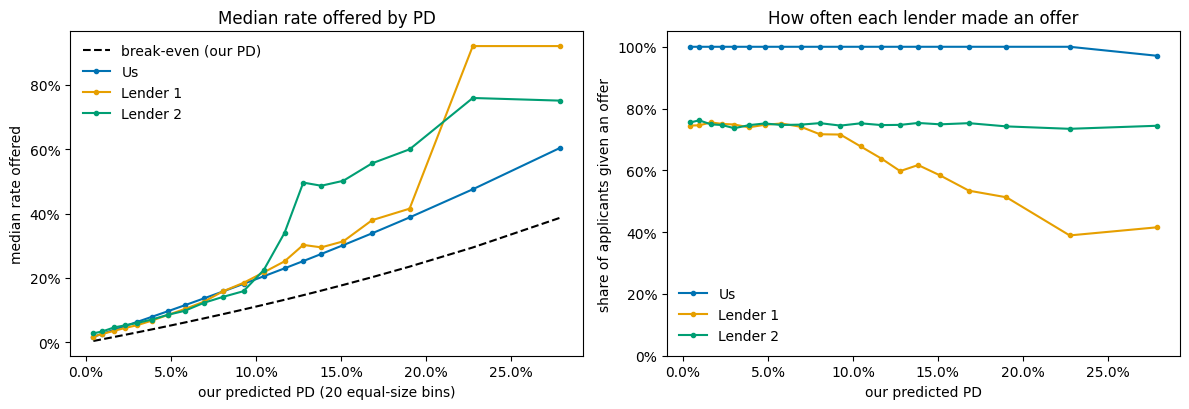

In [6]:
df["pd_bin"] = pd.qcut(df["pd"], 20)
curve = df.groupby("pd_bin", observed=True).agg(
    pd_mid=("pd", "median"), own=("own", "median"), competing1=("competing1", "median"),
    competing2=("competing2", "median"), break_even=("break_even", "median"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(curve["pd_mid"], curve["break_even"], "k--", lw=1.5, label="break-even (our PD)")
for color, (col, name) in zip(COLORS, [("own", "Us"), ("competing1", "Lender 1"), ("competing2", "Lender 2")]):
    ax.plot(curve["pd_mid"], curve[col], "o-", ms=3, color=color, label=name)
ax.set(xlabel="our predicted PD (20 equal-size bins)", ylabel="median rate offered", title="Median rate offered by PD")
ax.legend(frameon=False)

ax = axes[1]
offer_curve = df.groupby("pd_bin", observed=True).agg(
    pd_mid=("pd", "median"), **{name: (col, lambda s: s.notna().mean())
                                for col, name in [("own", "Us"), ("competing1", "Lender 1"), ("competing2", "Lender 2")]})
for color, name in zip(COLORS, ["Us", "Lender 1", "Lender 2"]):
    ax.plot(offer_curve["pd_mid"], offer_curve[name], "o-", ms=3, color=color, label=name)
ax.set(xlabel="our predicted PD", ylabel="share of applicants given an offer", title="How often each lender made an offer", ylim=(0, 1.05))
ax.legend(frameon=False)
for a in axes:
    a.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    a.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

## 2. Where we made and lost money, by risk bucket

Applicants are split into 10 equal-size buckets by **our** predicted PD (bucket 1 = safest, 10,000 applicants each). This section answers one question: **what should we change in Round 2?** It looks at three weak points:

- **2a. Adverse selection**: did we keep the bad borrowers and lose the good ones?
- **2b. Underpricing**: on loans we won, how much higher could our rate have been while still winning?
- **2c. Money left on the table**: how much more a better margin would have earned against the same rivals.

2b and 2c use hindsight (the rivals' actual offers), so they are upper bounds: they show **where** to change, not exact amounts we could have earned.

In [7]:
df["bucket"] = pd.qcut(df["pd"], N_BUCKETS, labels=False) + 1
x = np.arange(1, N_BUCKETS + 1)
won_mask = df["winner"] == "Us (L3)"

base = df.groupby("bucket").agg(
    our_pd=("pd", "mean"),
    default_all=("default", "mean"),
    win_rate=("accepted", "mean"),
    profit_M=("profit", lambda s: s.sum() / 1e6),
)
base["default_won"] = df[won_mask].groupby("bucket")["default"].mean()
base["avg_rate_won"] = df[won_mask].groupby("bucket")["own"].mean()
base.style.format({"our_pd": "{:.1%}", "default_all": "{:.1%}", "win_rate": "{:.0%}", "profit_M": "{:.2f}",
                   "default_won": "{:.1%}", "avg_rate_won": "{:.1%}"})

,our_pd,default_all,win_rate,profit_M,default_won,avg_rate_won
bucket,,,,,,
1,0.7%,0.8%,48%,0.67,0.8%,2.2%
2,2.0%,1.9%,46%,0.97,2.3%,4.5%
3,3.4%,3.9%,39%,1.04,4.1%,7.1%
4,5.3%,6.0%,36%,0.96,7.2%,10.6%
5,7.5%,7.6%,39%,1.76,9.0%,14.8%
6,9.9%,9.7%,44%,2.59,11.4%,19.4%
7,12.2%,12.1%,56%,4.25,13.4%,24.2%
8,14.5%,15.0%,56%,3.93,17.0%,29.0%
9,17.9%,17.5%,62%,6.26,19.2%,36.4%


### 2a. Adverse selection: default rate on loans we **won** vs loans we **lost**

If our pricing were not adversely selected, borrowers we won and borrowers we lost (in the same bucket) would default equally. When **lost** loans default *less* than **won** loans, rivals took the good borrowers (their private signal told them who was safe) and left us the rest: that is the winner's curse, bucket by bucket.

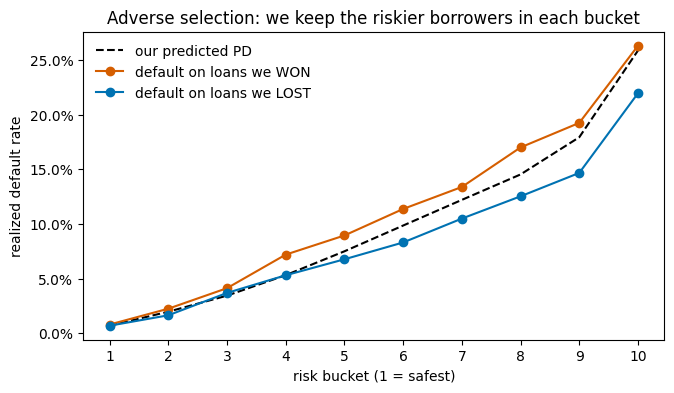

,default on won,default on lost,our PD,"gap (won - lost), pts"
bucket,,,,
1,0.8%,0.7%,0.7%,+0.1
2,2.3%,1.7%,2.0%,+0.6
3,4.1%,3.7%,3.4%,+0.4
4,7.2%,5.3%,5.3%,+1.9
5,9.0%,6.8%,7.5%,+2.2
6,11.4%,8.3%,9.9%,+3.1
7,13.4%,10.5%,12.2%,+2.9
8,17.0%,12.5%,14.5%,+4.5
9,19.2%,14.7%,17.9%,+4.6


In [8]:
lost_mask = (~won_mask) & df["own"].notna()
sel = pd.DataFrame({
    "default on won": df[won_mask].groupby("bucket")["default"].mean(),
    "default on lost": df[lost_mask].groupby("bucket")["default"].mean(),
    "our PD": base["our_pd"],
})
sel["gap (won - lost), pts"] = (sel["default on won"] - sel["default on lost"]) * 100

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(x, sel["our PD"], "k--", lw=1.5, label="our predicted PD")
ax.plot(x, sel["default on won"], "o-", color=COLORS[5], label="default on loans we WON")
ax.plot(x, sel["default on lost"], "o-", color=COLORS[0], label="default on loans we LOST")
ax.set(xlabel="risk bucket (1 = safest)", ylabel="realized default rate", xticks=x,
       title="Adverse selection: we keep the riskier borrowers in each bucket")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False)
plt.show()
sel.style.format({"default on won": "{:.1%}", "default on lost": "{:.1%}", "our PD": "{:.1%}",
                  "gap (won - lost), pts": "{:+.1f}"})

### 2b. Underpricing: how much rate did we give away on loans we won?

For each loan we won, the **highest rate that would still have won** is the cheapest rival offer (after the borrower's preference), plus 2% if the borrower prefers us; capped at 100%. If no rival made an offer, we could have charged up to 100%.

**Headroom = that highest winning rate − our rate.** Large headroom means we were much cheaper than we needed to be. "Interest given away" = headroom × 10,000 € on the loans that were repaid (on defaults the rate does not matter).

Total interest given away on repaid loans we won: 139.6 M€ (hindsight upper bound; our actual profit was 30.9 M€)


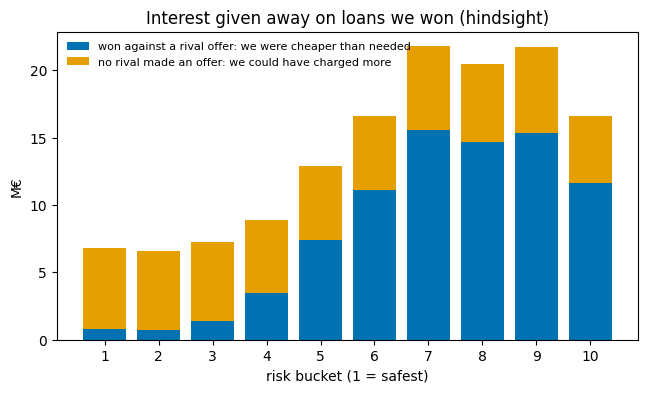

,median_headroom,share_won_with_no_rival_offer,interest_given_away_M,of which: no rival offered (M€)
bucket,,,,
1,2.0%,13%,6.82,6.05
2,1.7%,13%,6.56,5.81
3,2.0%,17%,7.28,5.90
4,3.9%,18%,8.92,5.48
5,14.4%,18%,12.86,5.49
6,35.5%,17%,16.61,5.51
7,47.3%,17%,21.77,6.23
8,59.7%,17%,20.43,5.73
9,55.0%,20%,21.70,6.35


In [9]:
rival_eff = np.column_stack([
    df["competing1"].fillna(np.inf) - BONUS * (df["borrowertype"] == 1),
    df["competing2"].fillna(np.inf) - BONUS * (df["borrowertype"] == 2),
]).min(axis=1)
max_win_rate = np.minimum(rival_eff + BONUS * (df["borrowertype"] == 3), 1.0)
df["headroom"] = np.where(won_mask, max_win_rate - df["own"], np.nan)
df["no_rival_offer"] = np.isinf(rival_eff)
df["interest_given_away"] = np.where(won_mask & (df["default"] == 0), df["headroom"] * LOAN, 0.0)

under = df[won_mask].groupby("bucket").agg(
    median_headroom=("headroom", "median"),
    share_won_with_no_rival_offer=("no_rival_offer", "mean"),
)
under["interest_given_away_M"] = df.groupby("bucket")["interest_given_away"].sum() / 1e6
under["of which: no rival offered (M€)"] = (df[df["no_rival_offer"]].groupby("bucket")["interest_given_away"].sum() / 1e6
                                            ).reindex(under.index, fill_value=0)
print(f"Total interest given away on repaid loans we won: {df['interest_given_away'].sum() / 1e6:.1f} M€ "
      f"(hindsight upper bound; our actual profit was {df['profit'].sum() / 1e6:.1f} M€)")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(x, under["interest_given_away_M"] - under["of which: no rival offered (M€)"], color=COLORS[0],
       label="won against a rival offer: we were cheaper than needed")
ax.bar(x, under["of which: no rival offered (M€)"], bottom=under["interest_given_away_M"] - under["of which: no rival offered (M€)"],
       color=COLORS[1], label="no rival made an offer: we could have charged more")
ax.set(xlabel="risk bucket (1 = safest)", ylabel="M€", xticks=x, title="Interest given away on loans we won (hindsight)")
ax.legend(frameon=False, fontsize=8)
plt.show()
under.style.format({"median_headroom": "{:.1%}", "share_won_with_no_rival_offer": "{:.0%}",
                    "interest_given_away_M": "{:.2f}", "of which: no rival offered (M€)": "{:.2f}"})

### 2c. Money left on the table: best margin per bucket

Keeping the rivals' actual offers and the borrowers' types fixed, we replay each bucket with rates `p/(1−p) + b·p` for many values of `b` and keep the most profitable. The submitted rule had `b = 0.75` (plus 1%).

This is a realistic version of 2b: one rate rule per bucket (we cannot see individual rival offers in advance). It is still in-sample, and rivals will change prices in Round 2.

Actual profit 30.9 M€ | best per-bucket margin 94.0 M€ | money left 63.1 M€ (hindsight)


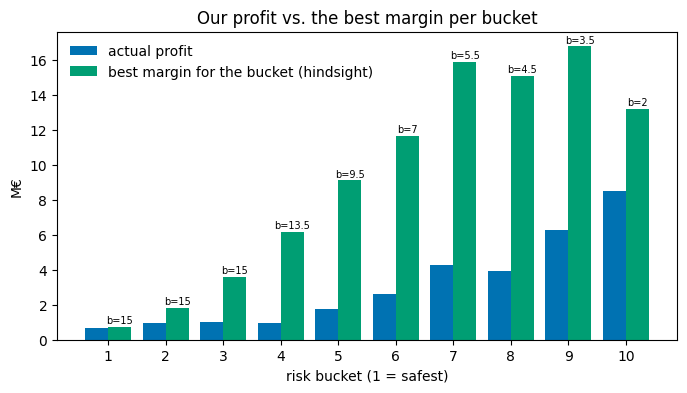

,actual profit M€,best b,best profit M€,loans won (actual),loans won (best b),of which no rival offer,money left M€
bucket,,,,,,,
1,0.67,15,0.73,"4,845",994,621,0.06
2,0.97,15,1.79,"4,616",634,623,0.82
3,1.04,15,3.58,"3,850",760,660,2.55
4,0.96,13.5,6.16,"3,598",954,658,5.21
5,1.76,9.5,9.11,"3,888","1,446",703,7.35
6,2.59,7,11.68,"4,440","1,965",763,9.09
7,4.25,5.5,15.88,"5,633","2,751",944,11.63
8,3.93,4.5,15.09,"5,611","2,911",973,11.16
9,6.26,3.5,16.78,"6,188","3,467","1,236",10.52


In [10]:
def our_profit_with(rate, rows):
    """Our profit on the selected rows if we had offered `rate` (rivals and types unchanged)."""
    rate = np.where(rate > 1, np.nan, rate)
    ours_eff = np.where(np.isnan(rate), np.inf, rate) - BONUS * (df.loc[rows, "borrowertype"].to_numpy() == 3)
    win = ours_eff < rival_eff[rows]
    pay = np.where(df.loc[rows, "default"].to_numpy() == 1, -LOAN, LOAN * np.nan_to_num(rate))
    return (win * pay).sum(), win.sum(), (win & np.isinf(rival_eff[rows])).sum()


B_GRID = np.round(np.arange(0.0, 15.01, 0.5), 2)
best_rows = []
for b_idx in range(1, N_BUCKETS + 1):
    rows = (df["bucket"] == b_idx).to_numpy()
    p = df.loc[rows, "pd"].to_numpy()
    results = {b: our_profit_with(p / (1 - p) + b * p, rows) for b in B_GRID}
    best_b = max(results, key=lambda b: results[b][0])
    best_rows.append({"bucket": b_idx, "actual profit M€": df.loc[rows, "profit"].sum() / 1e6,
                      "best b": best_b, "best profit M€": results[best_b][0] / 1e6,
                      "loans won (actual)": int(df.loc[rows, "accepted"].sum()), "loans won (best b)": int(results[best_b][1]),
                      "of which no rival offer": int(results[best_b][2])})
best = pd.DataFrame(best_rows).set_index("bucket")
best["money left M€"] = best["best profit M€"] - best["actual profit M€"]
print(f"Actual profit {best['actual profit M€'].sum():.1f} M€ | best per-bucket margin {best['best profit M€'].sum():.1f} M€ "
      f"| money left {best['money left M€'].sum():.1f} M€ (hindsight)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, best["actual profit M€"], 0.4, color=COLORS[0], label="actual profit")
ax.bar(x + 0.2, best["best profit M€"], 0.4, color=COLORS[2], label="best margin for the bucket (hindsight)")
for xi, b in zip(x, best["best b"]):
    ax.text(xi + 0.2, best.loc[xi, "best profit M€"] + 0.2, f"b={b:g}", ha="center", fontsize=7)
ax.set(xlabel="risk bucket (1 = safest)", ylabel="M€", xticks=x, title="Our profit vs. the best margin per bucket")
ax.legend(frameon=False)
plt.show()
best.style.format({"actual profit M€": "{:.2f}", "best profit M€": "{:.2f}", "money left M€": "{:.2f}", "best b": "{:g}",
                   "loans won (actual)": "{:,}", "loans won (best b)": "{:,}", "of which no rival offer": "{:,}"})

**How to read 2c.** In the middle buckets the best `b` is very large (rates of 50–100%). That is not a pricing recipe: at those rates we win almost only the applicants **no rival made an offer to** (about 9% of all applicants, see below), who accept any rate up to 100%. The lesson is twofold:

- On **contested** loans our margin was too thin (2b: we were often well below the rivals' prices in buckets 5–9).
- A sizeable group of applicants is **left unserved by rivals**; we served them too, but at our normal, low rate.

We cannot see in advance who the rivals will refuse, and rivals may change in Round 2, so the realistic target lies between `b = 0.75` and these hindsight values.

In [11]:
rival_none = np.isinf(rival_eff)
unserved = df.assign(no_rival_offer=rival_none).groupby("bucket").agg(
    share_no_rival_offer=("no_rival_offer", "mean"),
    our_pd=("pd", "mean"),
)
unserved["default_no_rival_offer"] = df[rival_none].groupby("bucket")["default"].mean()
unserved["default_all"] = df.groupby("bucket")["default"].mean()
print(f"Applicants with no rival offer: {rival_none.mean():.1%} | their default rate {df.loc[rival_none, 'default'].mean():.1%} "
      f"vs {df['default'].mean():.1%} overall")
unserved.style.format("{:.1%}")

Applicants with no rival offer: 8.8% | their default rate 13.6% vs 9.9% overall


,share_no_rival_offer,our_pd,default_no_rival_offer,default_all
bucket,,,,
1,6.2%,0.7%,0.3%,0.8%
2,6.2%,2.0%,2.4%,1.9%
3,6.6%,3.4%,3.8%,3.9%
4,6.6%,5.3%,6.8%,6.0%
5,7.0%,7.5%,8.4%,7.6%
6,7.6%,9.9%,10.5%,9.7%
7,9.4%,12.2%,13.0%,12.1%
8,9.7%,14.5%,17.1%,15.0%
9,12.4%,17.9%,19.3%,17.5%


## 3. Weak points in one place

Generated from the tables above.

In [12]:
worst_sel = sel["gap (won - lost), pts"].idxmax()
top_left = best["money left M€"].sort_values(ascending=False).head(3)
print("1. Margin too low overall: a higher margin would have earned "
      f"{best['best profit M€'].sum():.1f} M€ instead of {best['actual profit M€'].sum():.1f} M€ (hindsight upper bound, "
      "partly from applicants no rival served). "
      f"Best b per bucket ranges {best['best b'].min():g}–{best['best b'].max():g}, vs 0.75 submitted.")
print("2. Most money left in buckets " + ", ".join(f"{b} ({v:.1f} M€)" for b, v in top_left.items()) + ".")
print(f"3. Adverse selection: in {(sel['gap (won - lost), pts'] > 0).sum()} of 10 buckets our won loans default more than "
      f"the loans we lost; worst in bucket {worst_sel} ({sel.loc[worst_sel, 'gap (won - lost), pts']:+.1f} pts).")
no_offer_share = df.loc[won_mask, "no_rival_offer"].mean()
print(f"4. {no_offer_share:.0%} of our loans were won with no rival offer at all: there we competed only with the 100% cap. "
      f"Interest given away on those: {df.loc[df['no_rival_offer'], 'interest_given_away'].sum() / 1e6:.1f} M€.")
print(f"5. Borrowers who prefer us default less (10.1%) than those we win from rivals (~14%): "
      "the 2% preference is our safest source of profit.")

1. Margin too low overall: a higher margin would have earned 94.0 M€ instead of 30.9 M€ (hindsight upper bound, partly from applicants no rival served). Best b per bucket ranges 2–15, vs 0.75 submitted.
2. Most money left in buckets 7 (11.6 M€), 8 (11.2 M€), 9 (10.5 M€).
3. Adverse selection: in 10 of 10 buckets our won loans default more than the loans we lost; worst in bucket 9 (+4.6 pts).
4. 18% of our loans were won with no rival offer at all: there we competed only with the 100% cap. Interest given away on those: 57.5 M€.
5. Borrowers who prefer us default less (10.1%) than those we win from rivals (~14%): the 2% preference is our safest source of profit.
